# 4. Exploratory Data Visualization

This notebook provides a visual inspection of the final transformed time series. Its purpose is to visually confirm the stationarity of the data before it is used in the modeling phase.

The key steps are:
1.  **Load Transformed Data**: Executes the analysis notebook to load the `transformed_data` dictionary.
2.  **Define Reusable Plotting Functions**: Creates helper functions to generate standardized plots for single series (national data) and multi-series subplots (local data).
3.  **Generate Visualizations**: Creates a plot for each transformed variable in the specified Cholesky order (`indpro`, `cpi`, `fedfunds`, `permits`, `unemp`, `hpi`).

In [1]:
# Part 1: Load Transformed Data
# ==============================
# This cell executes the `3_econometric_analysis.ipynb` notebook to ensure all
# data transformations and stationarity tests have been run. It loads the
# `transformed_data` dictionary into the current environment.

%run ./3_econometric_analysis.ipynb

# Import additional libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

Loading cached data for National...
Loading cached data for SF...
Loading cached data for DET...
Loading cached data for ATL...
Loading cached data for LV...
\nData loading complete.
\nSample of raw data for SF:
             indpro    cpi  fedfunds        hpi  unemp      permits
date                                                               
1991-01-01  61.0842  134.7      6.91  71.935495    4.6  2037.040992
1991-02-01  60.6387  134.8      6.25  71.126390    4.7   585.889721
1991-03-01  60.2973  134.8      6.12  70.608208    4.9   835.829789
1991-04-01  60.4524  135.1      5.91  69.909268    5.0   789.687733
1991-05-01  61.0587  135.6      5.78  70.010559    5.1   625.659862
Processed 'indpro' (raw and log-difference).
Processed 'cpi' (raw and log-difference).
Processed 'fedfunds' (raw and first-difference).
Processed 'permits' for all areas (raw and log-difference).
Processed 'unemp' for all areas (raw and first-difference).
Processed 'hpi' for all areas (raw and log-difference).


In [2]:
# Part 2: Reusable Plotting Functions
# ====================================
# To create clean and consistent visualizations, we define two helper functions:
# - `plot_single_series`: For plotting a single time series (e.g., national data).
# - `plot_area_subplots`: For creating a grid of subplots for multi-area data.

def plot_single_series(series: pd.Series, title: str, ylabel: str):
    """
    Generates a standardized line plot for a single time series.
    """
    if series is None or series.empty:
        print(f"Data for '{title}' not found or is empty. Skipping plot.")
        return
        
    plt.figure(figsize=(14, 7))
    sns.lineplot(data=series)
    plt.title(title, fontsize=16)
    plt.xlabel('Date')
    plt.ylabel(ylabel)
    plt.grid(True)
    plt.show()

def plot_area_subplots(df: pd.DataFrame, title: str, ylabel: str):
    """
    Generates a grid of subplots for a DataFrame with multiple columns (areas).
    """
    if df is None or df.empty:
        print(f"Data for '{title}' not found or is empty. Skipping plot.")
        return

    areas = df.columns
    n_areas = len(areas)
    n_cols = 3
    n_rows = (n_areas + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4), sharex=True, sharey=True)
    fig.suptitle(title, fontsize=18)
    axes = axes.flatten()
    
    for i, area in enumerate(areas):
        sns.lineplot(ax=axes[i], data=df, x=df.index, y=area)
        axes[i].set_title(f'{area}')
        axes[i].set_xlabel('Date')
        axes[i].set_ylabel(ylabel)
        axes[i].grid(True)
        
    # Hide any unused subplots
    for i in range(n_areas, len(axes)):
        axes[i].set_visible(False)
        
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    plt.show()

# Part 3: Generate Visualizations
# ================================
# We now use the helper functions to plot each of our final transformed
# variables in the correct Cholesky order.

### 3.1 Industrial Production (indpro_log_diff)

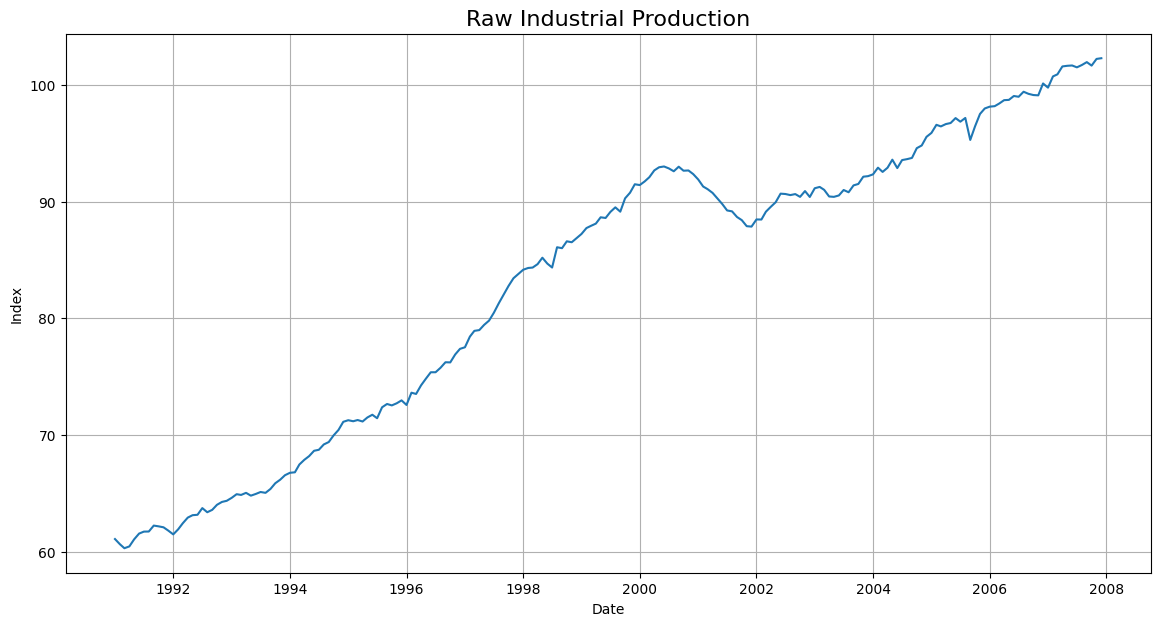

In [3]:
plot_single_series(
    transformed_data.get('indpro_raw'),
    title='Raw Industrial Production',
    ylabel='Index'
)

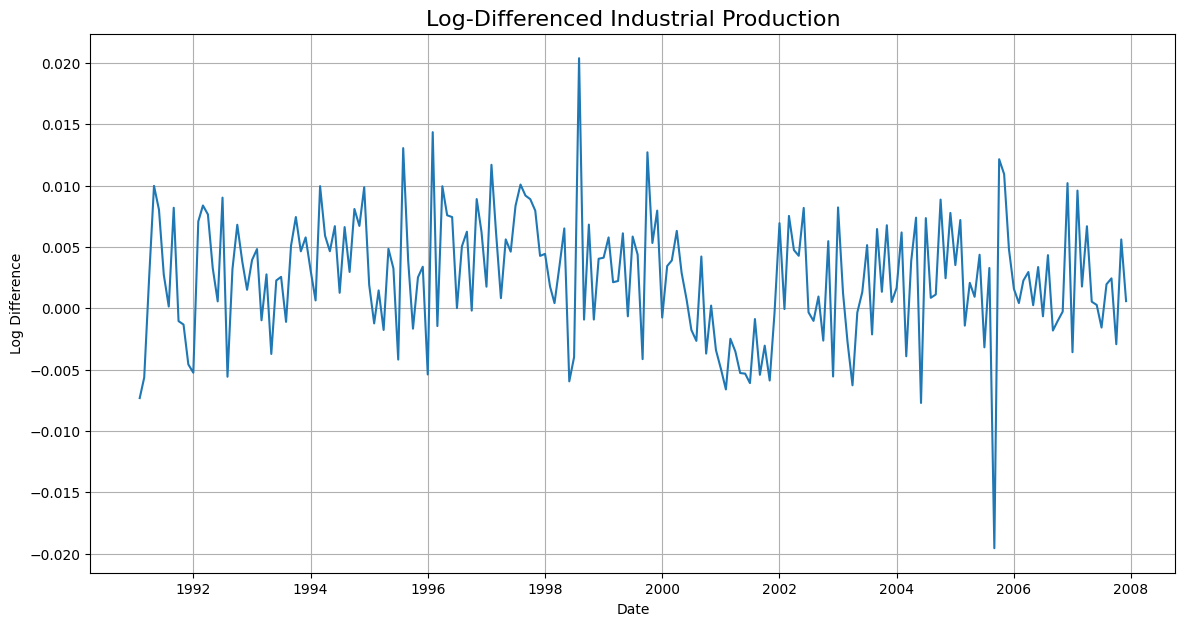

In [4]:
plot_single_series(
    transformed_data.get('indpro_log_diff'),
    title='Log-Differenced Industrial Production',
    ylabel='Log Difference'
)

### 3.2 Consumer Price Index (cpi_log_diff)

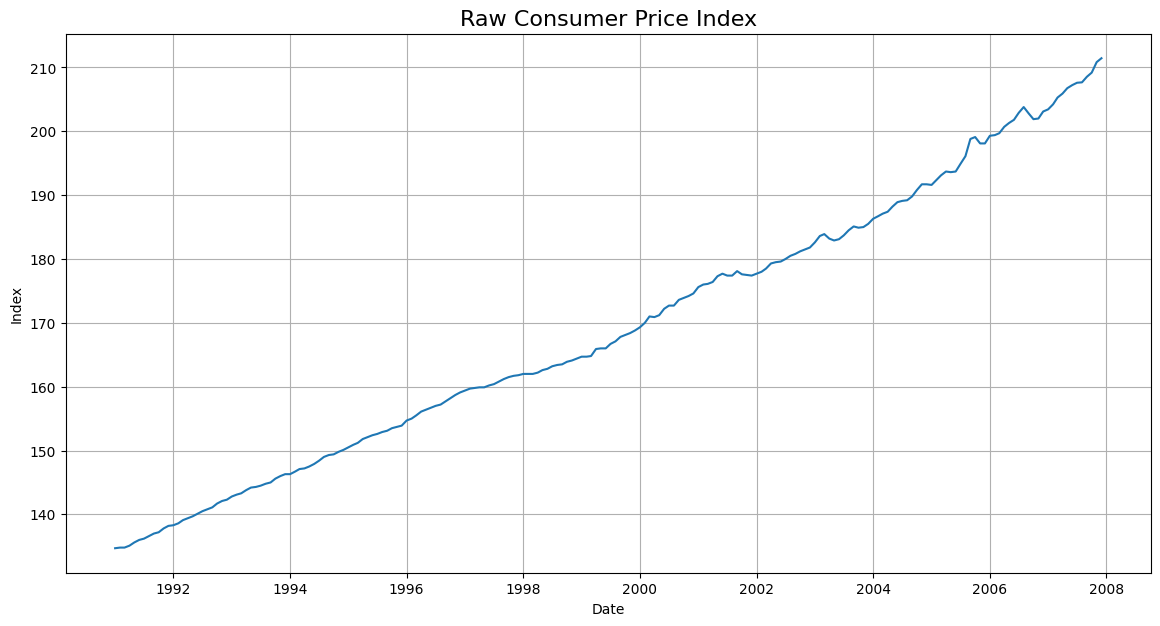

In [5]:
plot_single_series(
    transformed_data.get('cpi_raw'),
    title='Raw Consumer Price Index',
    ylabel='Index'
)

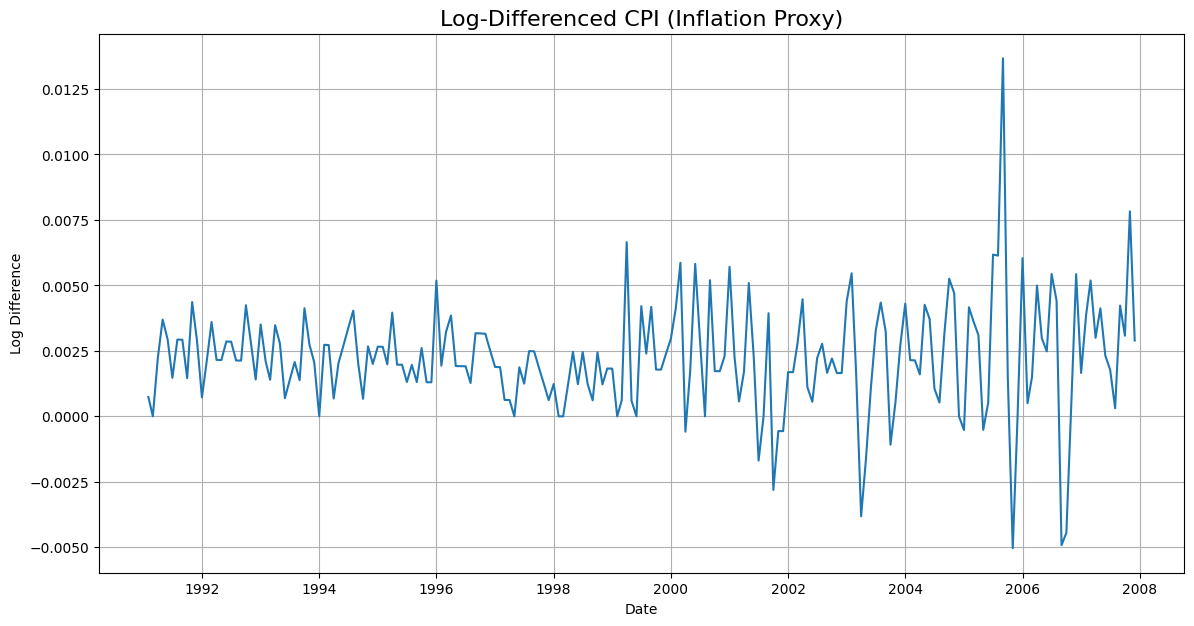

In [6]:
plot_single_series(
    transformed_data.get('cpi_log_diff'),
    title='Log-Differenced CPI (Inflation Proxy)',
    ylabel='Log Difference'
)

### 3.3 Federal Funds Rate (fedfunds_diff)

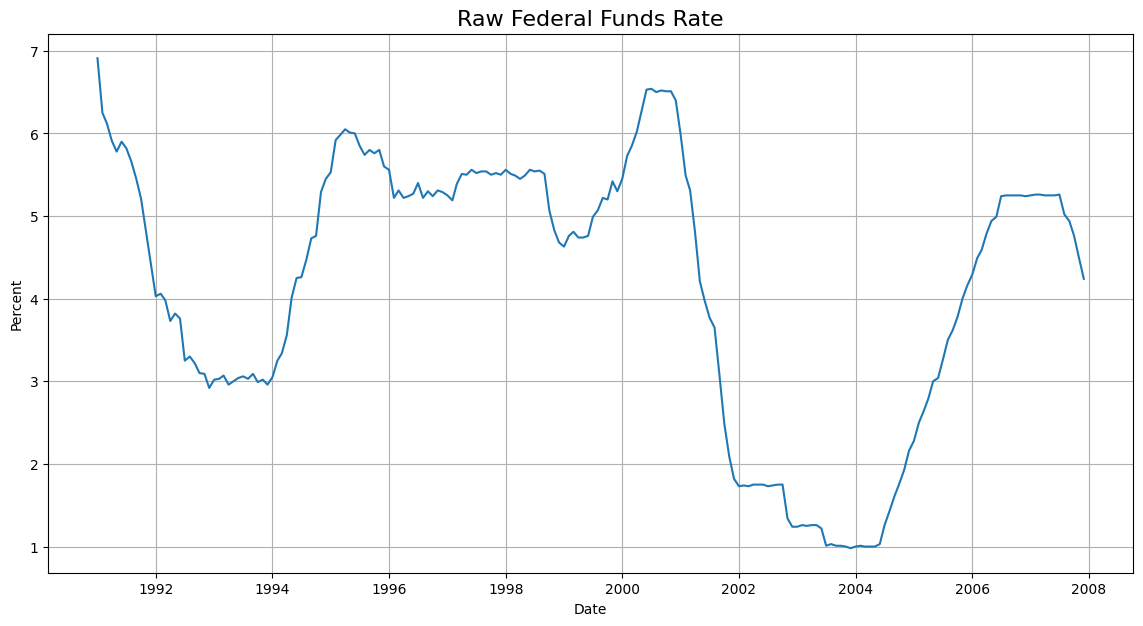

In [7]:
plot_single_series(
    transformed_data.get('fedfunds_raw'),
    title='Raw Federal Funds Rate',
    ylabel='Percent'
)

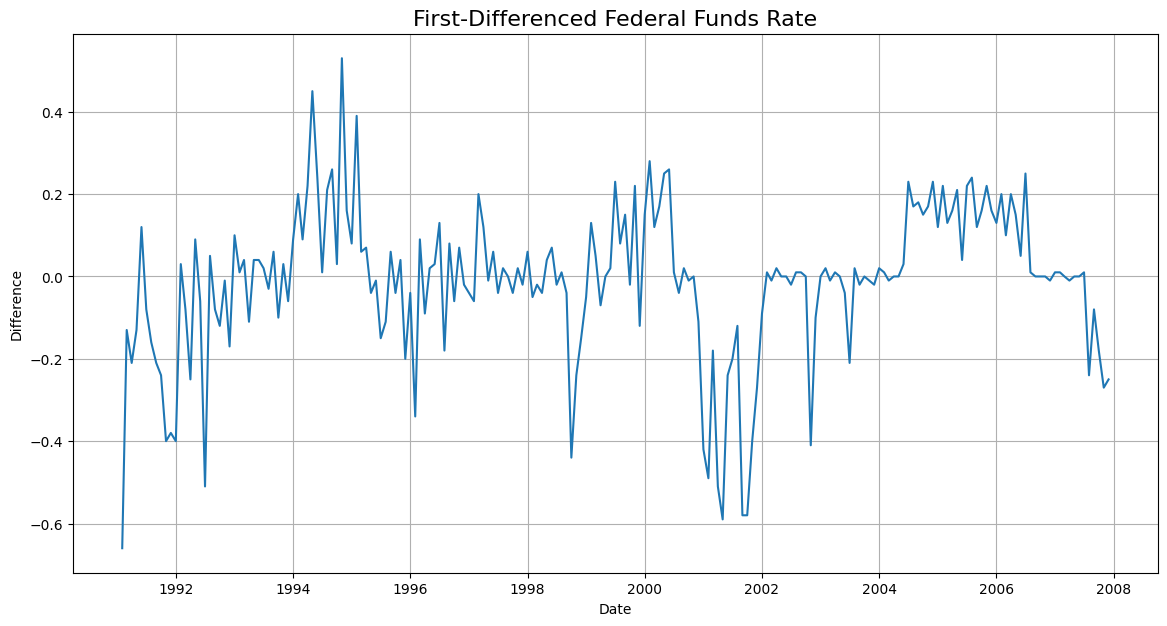

In [8]:
plot_single_series(
    transformed_data.get('fedfunds_diff'),
    title='First-Differenced Federal Funds Rate',
    ylabel='Difference'
)

### 3.4 Building Permits (permits_log_diff)

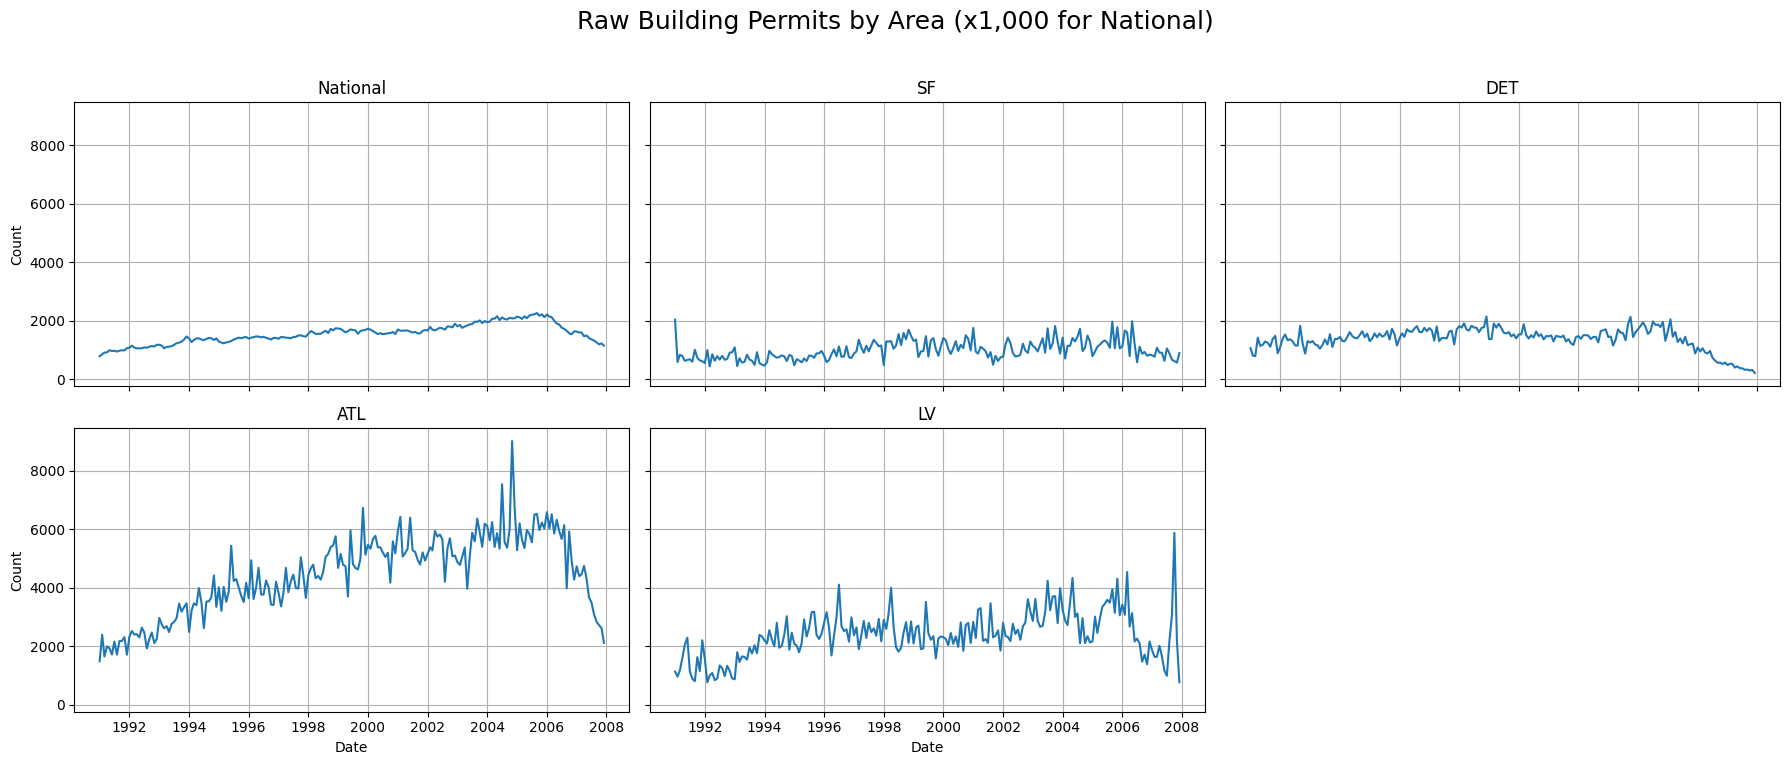

In [9]:
plot_area_subplots(
    transformed_data.get('permits_raw'),
    title='Raw Building Permits by Area (x1,000 for National)',
    ylabel='Count'
)

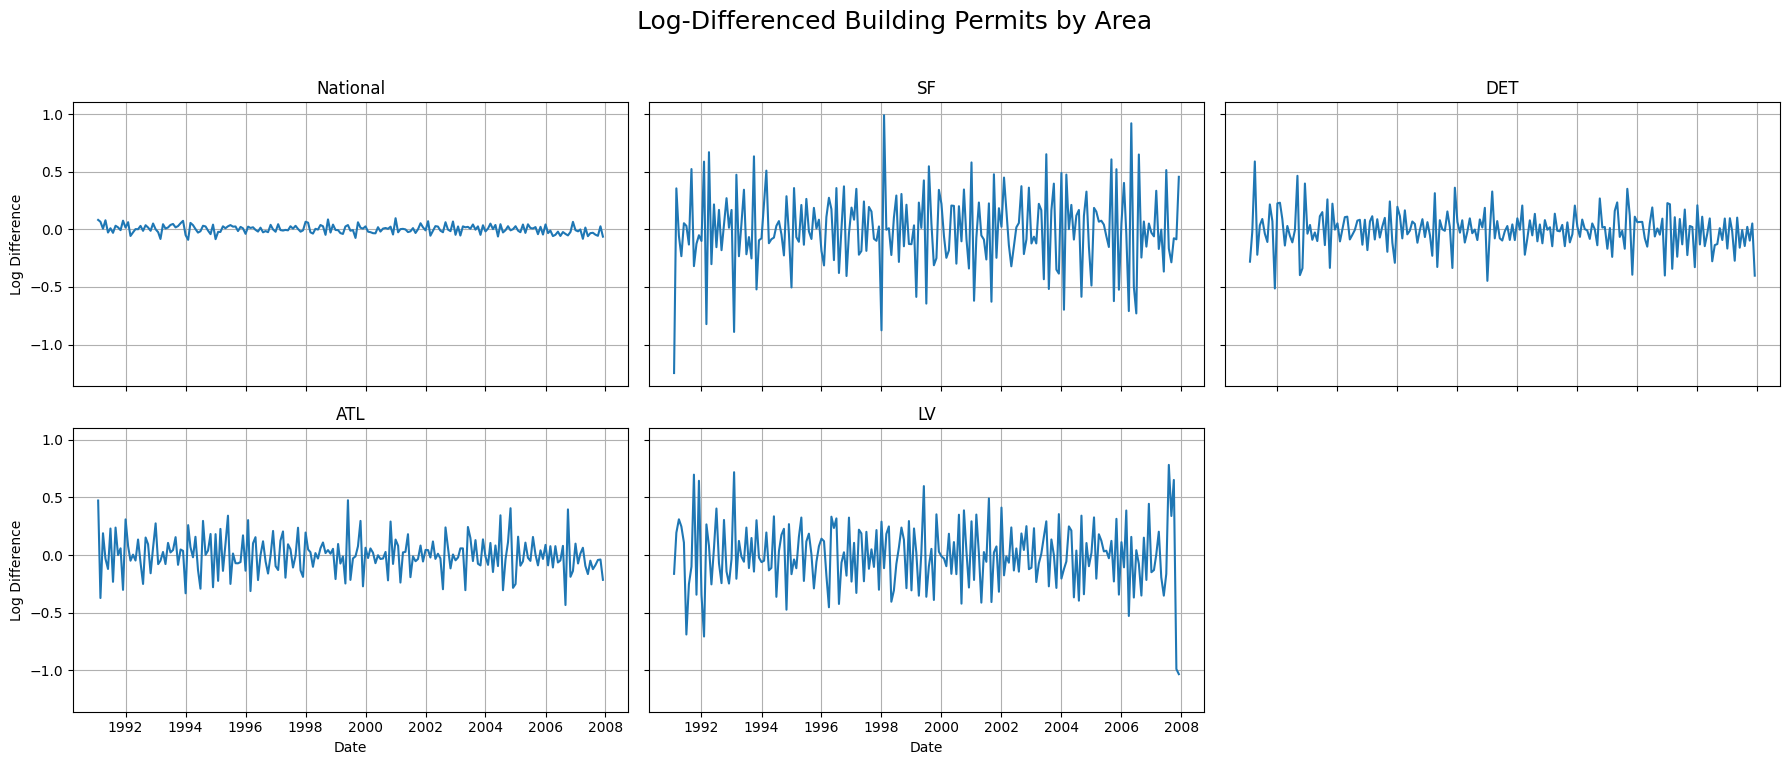

In [10]:
plot_area_subplots(
    transformed_data.get('permits_log_diff'),
    title='Log-Differenced Building Permits by Area',
    ylabel='Log Difference'
)

### 3.5 Unemployment (unemp_diff)

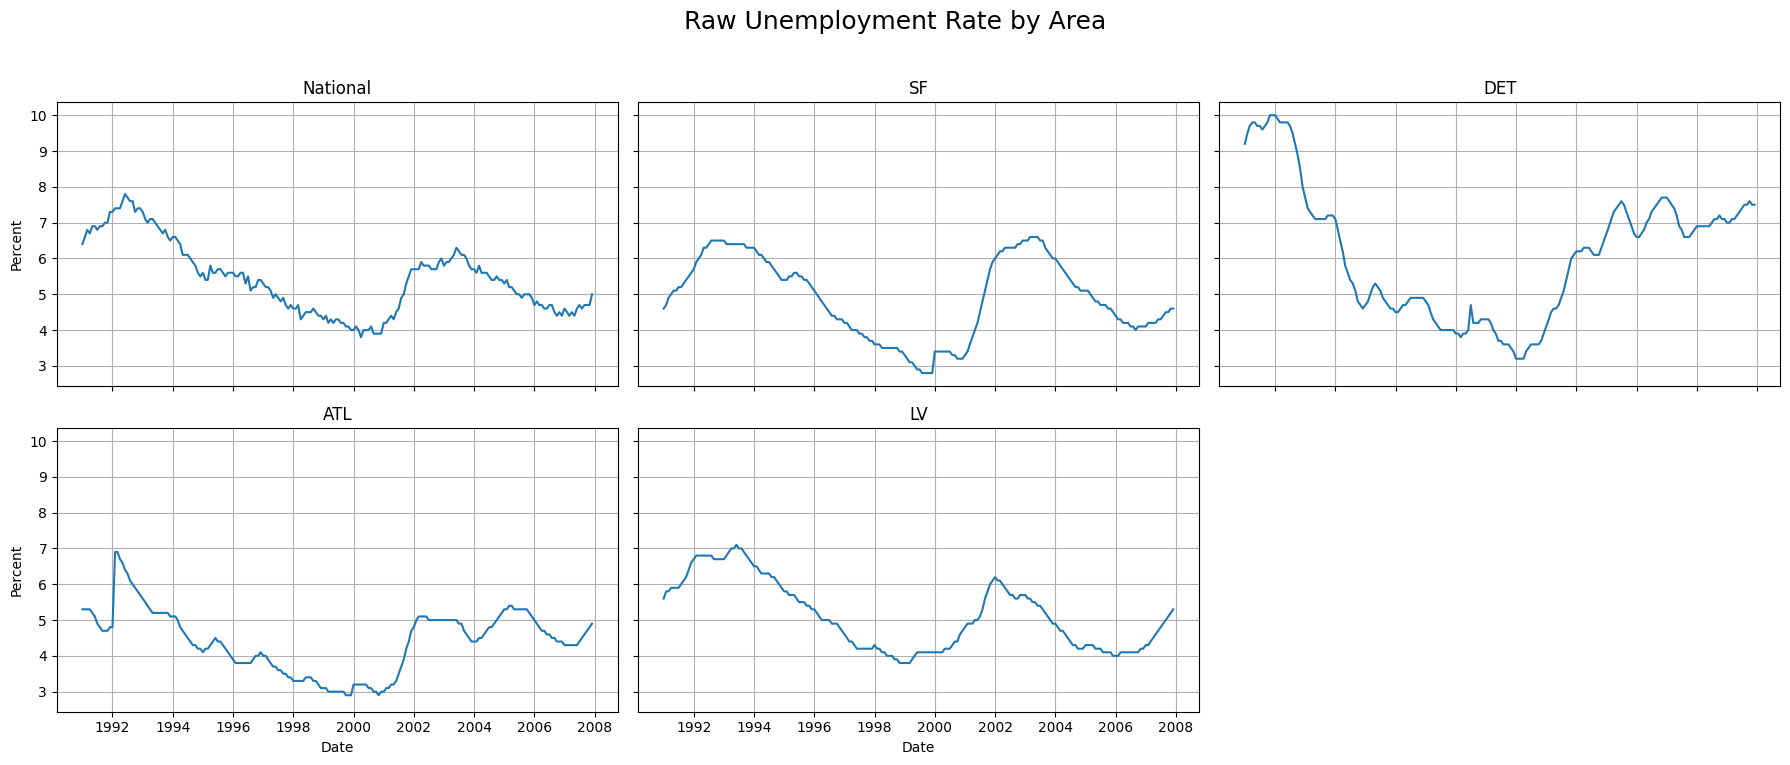

In [11]:
plot_area_subplots(
    transformed_data.get('unemp_raw'),
    title='Raw Unemployment Rate by Area',
    ylabel='Percent'
)

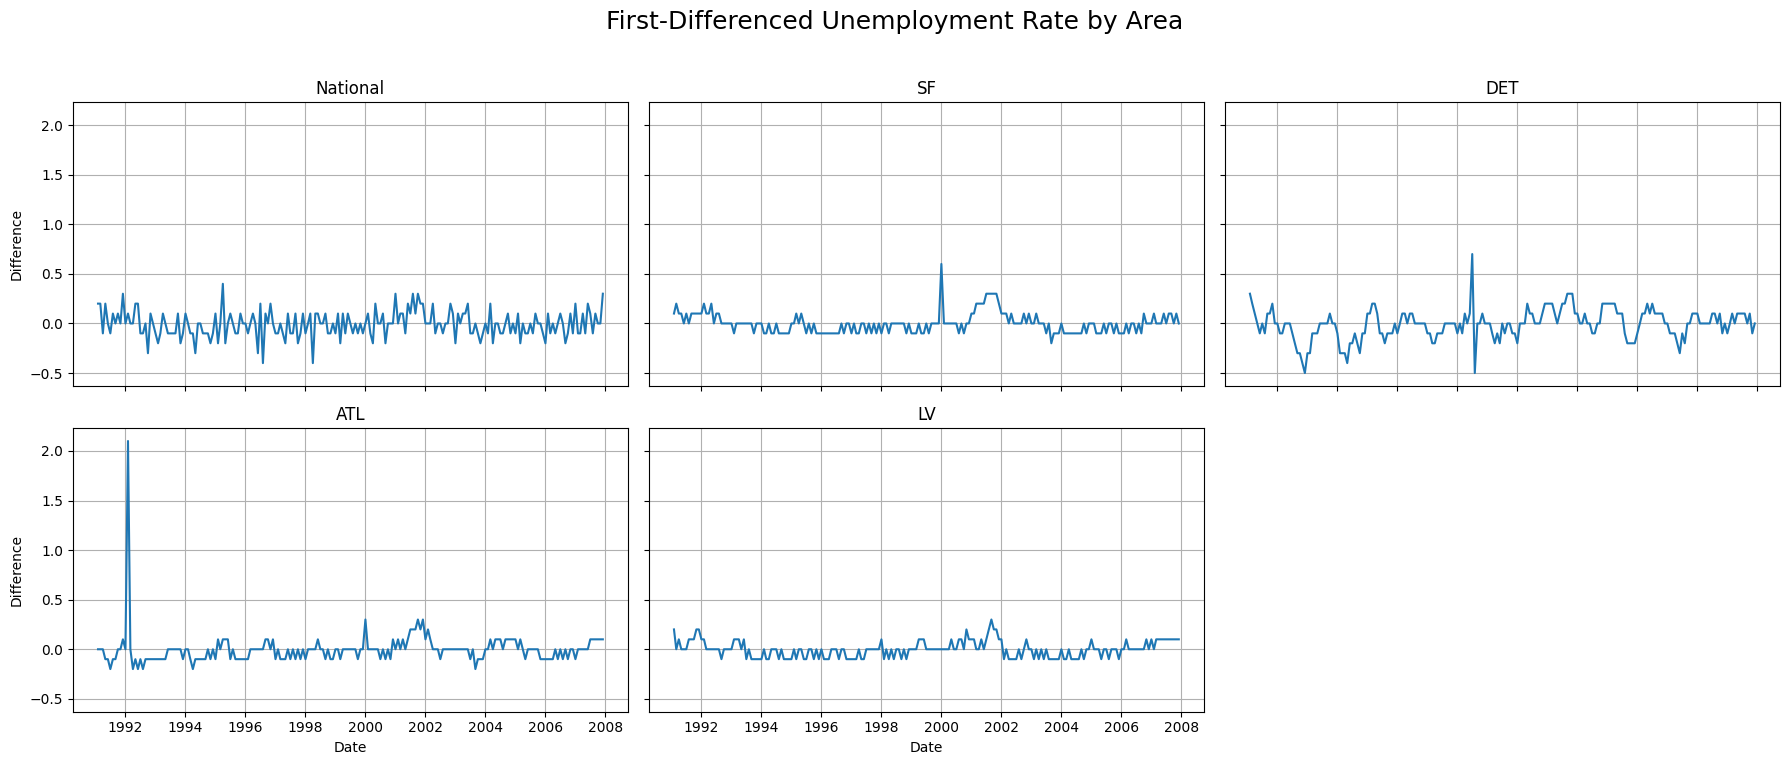

In [12]:
plot_area_subplots(
    transformed_data.get('unemp_diff'),
    title='First-Differenced Unemployment Rate by Area',
    ylabel='Difference'
)

### 3.6 House Price Index (hpi_log_diff)

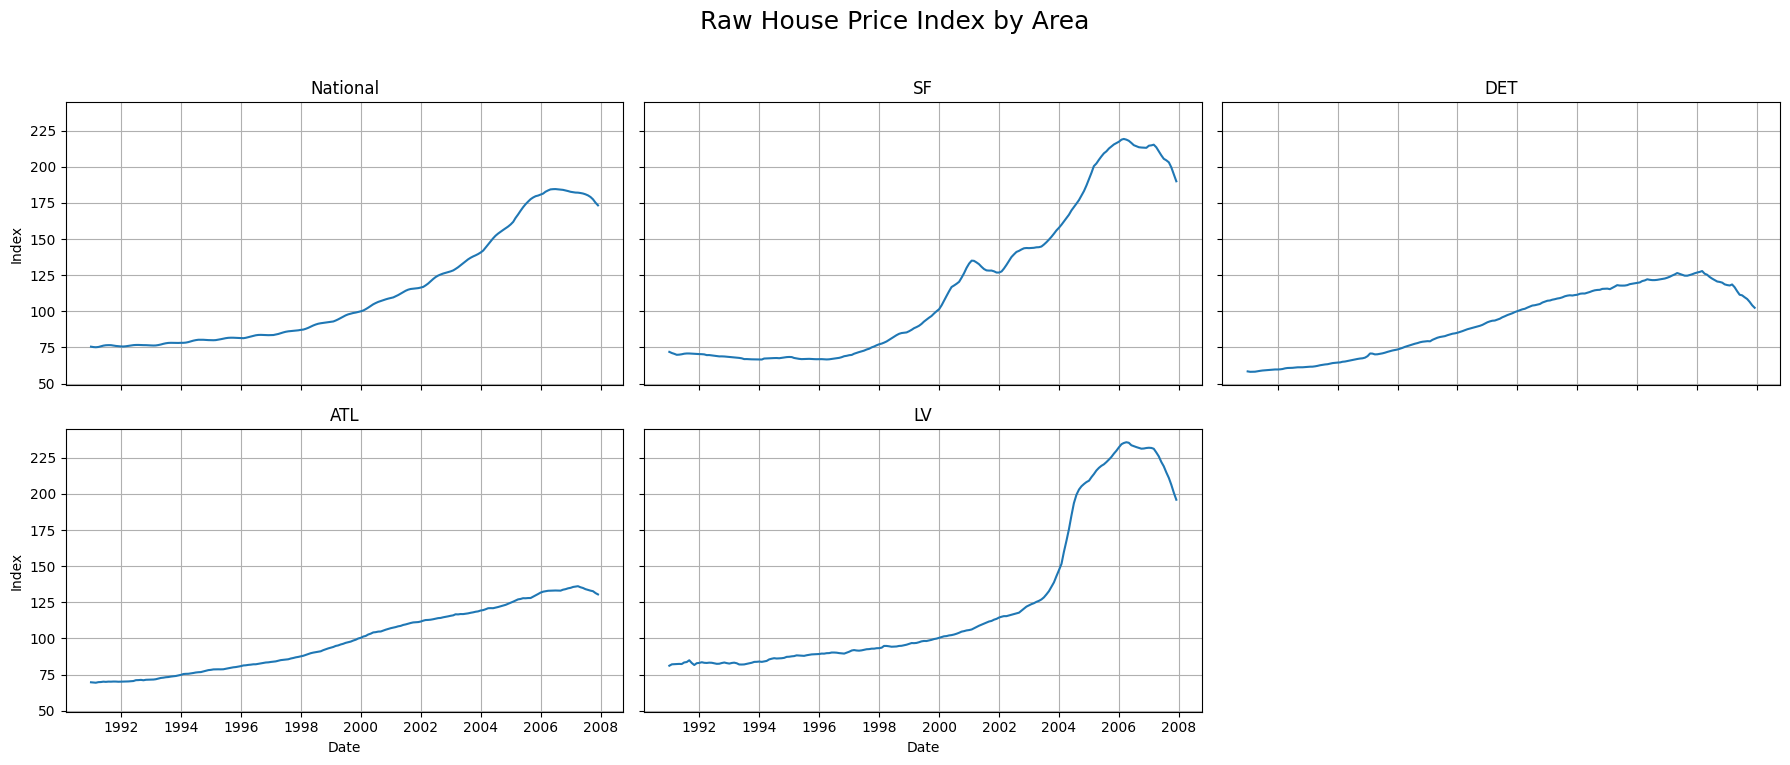

In [13]:
plot_area_subplots(
    transformed_data.get('hpi_raw'),
    title='Raw House Price Index by Area',
    ylabel='Index'
)

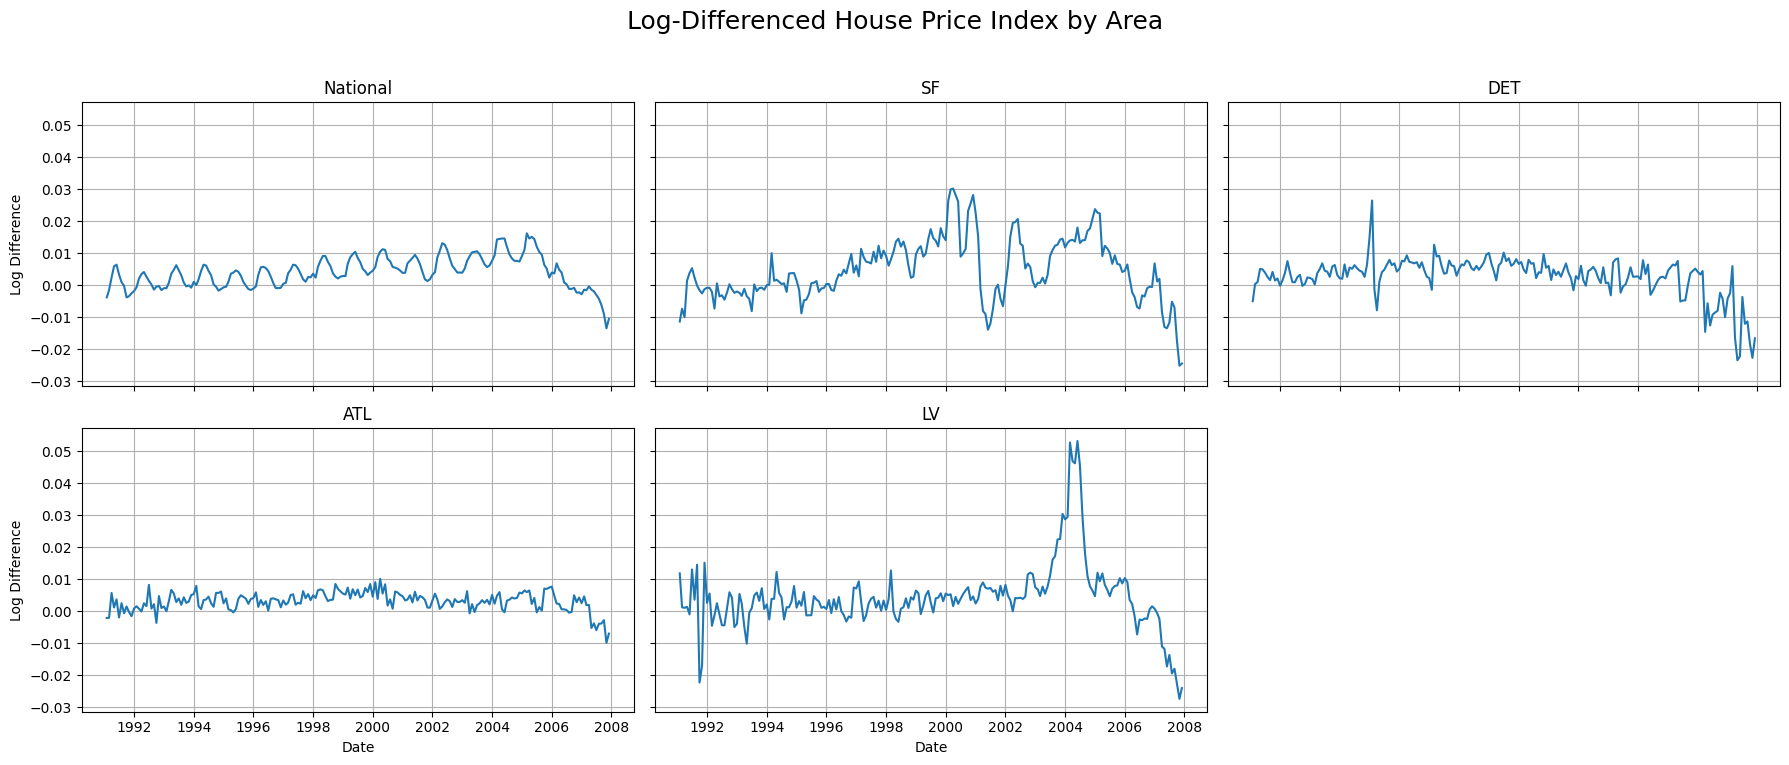

In [14]:
plot_area_subplots(
    transformed_data.get('hpi_log_diff'),
    title='Log-Differenced House Price Index by Area',
    ylabel='Log Difference'
)